/var/folders/w6/n78q49k13z3cct9wmrgv4qd40000gn/T/ipykernel_28542/3075308597.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_player['Mat'] = df_player.groupby('Played In')['Inns'].transform('sum')
/var/folders/w6/n78q49k13z3cct9wmrgv4qd40000gn/T/ipykernel_28542/3075308597.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_player['Centuries per Match (%)'] = (df_player['100s'] / df_player['Mat']) * 100
/var/folders/w6/n78q49k13z3cct9wmrgv4qd40000gn/T/ipykernel_28542/3075308597.py:17: SettingWithC

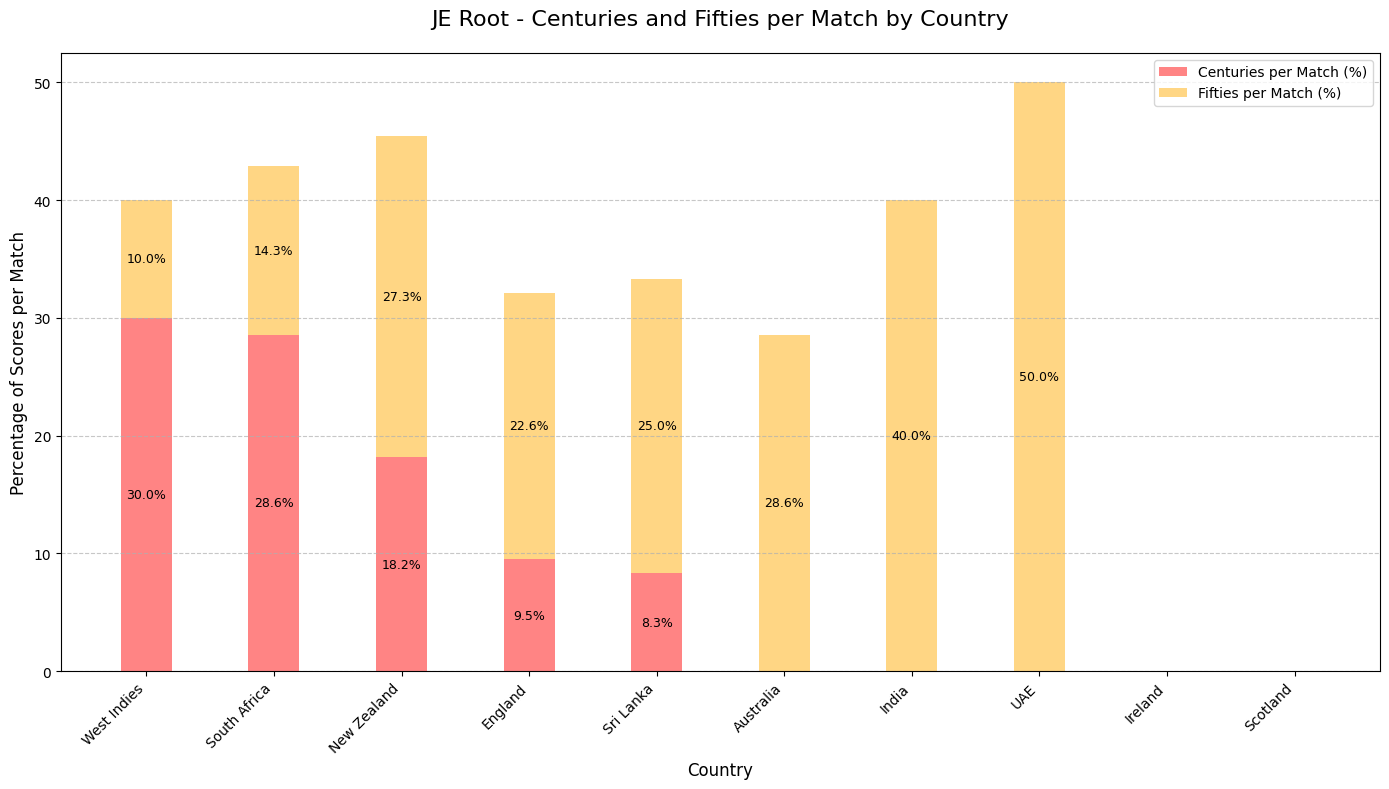

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('all_player_Country_stats.csv')

player_name = "JE Root"

df_player = df[df['Player Name'].str.contains(player_name, case=False, na=False)]

if df_player.empty:
    print(f"No data found for {player_name}.")
else:
    df_player['Mat'] = df_player.groupby('Played In')['Inns'].transform('sum')

    df_player['Centuries per Match (%)'] = (df_player['100s'] / df_player['Mat']) * 100
    df_player['Fifties per Match (%)'] = (df_player['50s'] / df_player['Mat']) * 100

    # Sort the dataframe by Centuries per Match (%) for better visualization
    df_player = df_player.sort_values(by='Centuries per Match (%)', ascending=False)

    plt.figure(figsize=(14, 8))

    bars1 = plt.bar(df_player['Played In'], df_player['Centuries per Match (%)'], color='#ff6666', alpha=0.8, label='Centuries per Match (%)', width=0.4)

    bars2 = plt.bar(df_player['Played In'], df_player['Fifties per Match (%)'], color='#ffcc66', alpha=0.8, label='Fifties per Match (%)', bottom=df_player['Centuries per Match (%)'], width=0.4)

    for bar in bars1:
        height = bar.get_height()
        if height > 0:
            plt.text(bar.get_x() + bar.get_width() / 2.0, height / 2.0,
                     f'{height:.1f}%', ha='center', va='center', color='black', fontsize=9)

    for bar in bars2:
        height = bar.get_height()
        base = bar.get_y()
        if height > 0:
            plt.text(bar.get_x() + bar.get_width() / 2.0, base + height / 2.0,
                     f'{height:.1f}%', ha='center', va='center', color='black', fontsize=9)

    plt.title(f'{player_name} - Centuries and Fifties per Match by Country', fontsize=16, pad=20)
    plt.ylabel('Percentage of Scores per Match', fontsize=12)
    plt.xlabel('Country', fontsize=12)
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.legend()

    plt.tight_layout()
    plt.show()
